# PIMC - Proton in a double well potential

In [475]:
import numpy as np
import scipy.constants as const

# Constants
P = 50 # Number of beads 
N = int(10e4) # Number of iterations
a = 0.04e-9 # Potential lenght parameter
C = 0.3 # Unit reduction factor
m = const.m_e # electron mass
V0 = const.hbar**2 / (2 * m * a**2 * C) # Potential energy parameter
T = 0.4 * V0 / const.k # Simulation temperature
dx = 0.4 * a # Spatial step size (to be fine-tuned)
omega_P = np.sqrt(P) * const.k * T / const.hbar # Quantum spring frequency

# Functions
def random_displacement(dx):
    """
    Generate a random displacement following dx*(eta-0.5), where eta is a uniform random number in [0, 1].
    """
    eta = np.random.uniform(0, 1)
    return dx * (2 * eta - 1)

def V(x):
    """
    Potential energy function.
    """
    return V0 * ((x / a)**2 - 1)**2

def Delta_U(state, bead_index, displacement):
    """
    Calculate the change in potential energy for a given bead index and displacement.
    """
    # Compute the diff in potential energy
    V_diff = (1/P) * (V(state[bead_index] + displacement) - V(state[bead_index]))

    # Compute the diff in spring energy
    xj_old = state[bead_index]
    xj_new = xj_old + displacement
    xjp = state[(bead_index + 1) % P]
    xjm = state[(bead_index - 1) % P]
    spring_diff = 0.5 * m * omega_P**2 * ((xjp - xj_new)**2 + (xj_new - xjm)**2 - (xjp - xj_old)**2 - (xj_old - xjm)**2)
    return V_diff + spring_diff

def metropolis_acceptance(delta_U):
    """
    Metropolis acceptance criterion.
    """
    if delta_U < 0:
        return True
    else:
        acceptance_prob = np.exp(-delta_U / (const.k * T))
        return np.random.uniform(0, 1) <= acceptance_prob

def algo_step(M_conf, success_list, i):
    """
    Perform a single step of the Metropolis algorithm.
    """
    # Randomly select a bead index
    bead_index = np.random.randint(0, P)

    # Generate a random displacement
    displacement = random_displacement(dx)

    # Calculate the change in potential energy
    delta_U = Delta_U(M_conf[i, :], bead_index, displacement)

    # Decide whether to accept the move
    M_conf[i+1, :] = M_conf[i, :] # Copy previous configuration
    if metropolis_acceptance(delta_U):
        M_conf[i+1, bead_index] += displacement
        success_list[i] = 1  # Move accepted
        return True  # Move accepted
    else:
        success_list[i] = 0  # Move rejected
        return False  # Move rejected

def run_simulation(N):
    """
    Run the Metropolis algorithm for N iterations.
    """

    # Initialization
    M_conf = a*np.ones((N+1, P)) # Configuration matrix for beads
    success_list = np.zeros(N, dtype=int) # List to store success rates

    for i in range(int(N)):
        algo_step(M_conf, success_list, i)

    return (M_conf, success_list)

# Run simulation

In [476]:
M_conf, success_list = run_simulation(100000)

# Result analysis

Success rate: 46.01%
Mean energy: 2.9306e+01 eV
Variance of energy: 2.0635e+02 eV^2
Mean centroid position: 3.9115e-11 m
Mean controid position (reduced units): 9.7788e-01 a
Variance of centroid position: 3.3348e-23 m^2


Text(0.5, 1.0, 'Distribution of centroid positions (reduced units)')

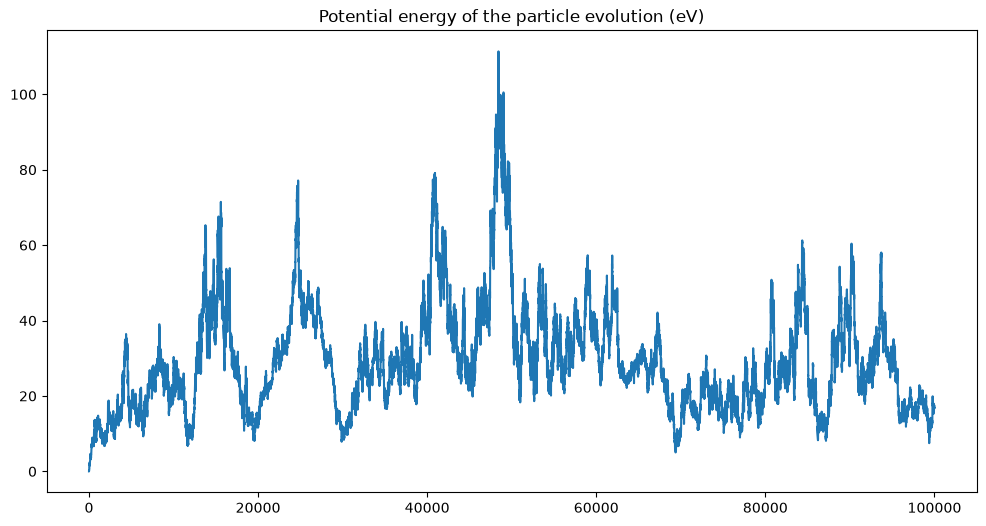

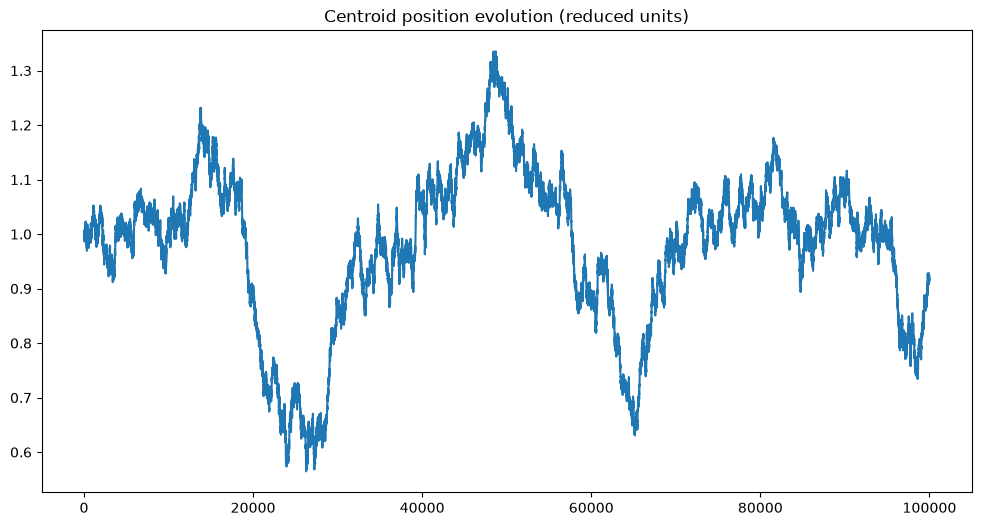

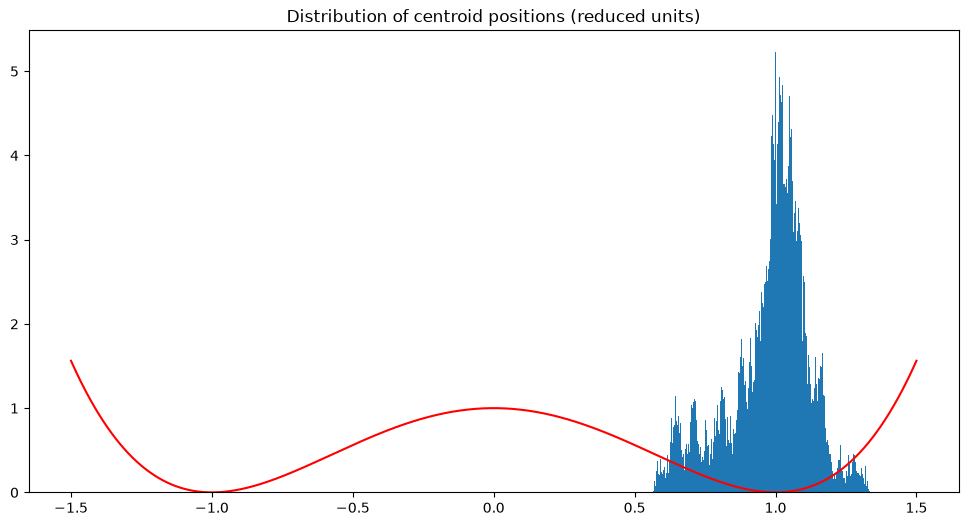

In [482]:
# Success rate calculation (should be between 40% and 50%, if not change dx)
success_rate = np.mean(success_list) * 100
print(f"Success rate: {success_rate:.2f}%")

# Mean energy calculation
def mean_energy(M_conf):
    """
    Calculate the mean energy of the system for each configuration (<V> = 1/P * Sum(s=1 to P) V(x_s)).
    """
    return (1/P) *np.sum(V0 * ((M_conf / a)**2 - 1)**2, axis=1)

mean_energies = mean_energy(M_conf)
print(f"Mean energy: {np.mean(mean_energies) / const.e:.4e} eV")
print(f"Variance of energy: {np.var(mean_energies) / (const.e**2):.4e} eV^2")

# Centroid distribution calculation
def centroid_distribution(M_conf):
    """
    Calculate the centroid distribution of the system (x_c = 1/P * Sum(s=1 to P) x_s).
    """
    return (1/P) * np.sum(M_conf, axis=1)

centroid_positions = centroid_distribution(M_conf)
print(f"Mean centroid position: {np.mean(centroid_positions):.4e} m")
print(f"Mean controid position (reduced units): {np.mean(centroid_positions) / a:.4e} a")
print(f"Variance of centroid position: {np.var(centroid_positions):.4e} m^2")

# Plots
import matplotlib.pyplot as plt

## Plot energy evolution
plt.figure(figsize=(12, 6))
plt.plot(mean_energies / const.e)
plt.title('Potential energy of the particle evolution (eV)')

## Plot centroid (reduced positions)
plt.figure(figsize=(12, 6))
plt.plot(centroid_positions/a)
plt.title('Centroid position evolution (reduced units)')

# Plot distribution of centroid positions (reduced position)
plt.figure(figsize=(12, 6))
plt.hist(centroid_positions/a, bins=500, density=True)
plt.plot(np.linspace(-1.5, 1.5, 1000),  ((np.linspace(-1.5, 1.5, 1000))**2 - 1)**2, color='red', label='Double well potential')
plt.title('Distribution of centroid positions (reduced units)')


